# Pareto Analysis – Maven Fuzzy Factory (Mini project)

## 1. Introduction

### 1.1. Analysis objective
Apply the Pareto principle (80/20) to the sales data of an online stuffed-toy store to find the **small group of products that generates most of the revenue and gross profit**, and decide where resources should be focused.

### 1.2. Analysis questions
1. Overview: what are the revenue, gross profit, number of orders and average order value (AOV)?
2. How did revenue change over time?
3. Which products generate 80% of revenue and gross profit? Does the result change when products are compared over the same period?

### 1.3. Dataset description
- Source: the Maven Fuzzy Factory e-commerce dataset, described in *Data Dictionary.docx*.
- Data type: **several relational tables** (unlike Netflix, which is one big table). The notebook uses 3 tables:

| Table | Primary key (PK) | Foreign keys (FK) | Content |
|---|---|---|---|
| `orders` | order_id | website_session_id, user_id, primary_product_id | 1 row = 1 order |
| `order_items` | order_item_id | order_id, product_id | 1 row = 1 product in an order |
| `products` | product_id | – | Product catalog |

- The other tables in the data dictionary (`order_item_refunds`, `website_sessions`, `website_pageviews`) are not needed for the Pareto questions → not used.

## 2. Preparation

### 2.1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns

pd.set_option('display.max_columns', None) # let pandas display every column of a dataframe
pd.set_option('display.float_format', '{:.2f}'.format) # show only 2 decimal places

# Shared color palette for every chart (categorical: blue -> orange -> teal...)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10,
})

In [2]:
import sys
print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"seaborn version: {sns.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.18
pandas version: 2.2.3
matplotlib version: 3.10.0
seaborn version: 0.13.2
numpy version: 2.5.4


### 2.2. Load data
On Colab the files were read from Google Drive (`/content/drive/...`). In VS Code the notebook runs with the notebook's folder as the working directory, and the CSV files are in the same folder, so only the file names are needed.

The `created_at` column is converted to `datetime` while reading the files with `parse_dates`, so no separate format-standardisation step is needed.

In [3]:
orders   = pd.read_csv('orders.csv', parse_dates=['created_at'])
items    = pd.read_csv('order_items.csv', parse_dates=['created_at'])
products = pd.read_csv('products.csv', parse_dates=['created_at'])

tables = {'orders': orders, 'order_items': items, 'products': products}

## 3. Data overview

### 3.1. Data size before cleaning

In [4]:
shape_before = {name: t.shape for name, t in tables.items()}
display(shape_before)  # (rows, columns)

{'orders': (32313, 8), 'order_items': (40025, 7), 'products': (4, 3)}

### 3.2. Data type of each column

In [5]:
for name, t in tables.items():
    print(f'===== {name} =====')
    t.info()
    print()

===== orders =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            32313 non-null  int64         
 1   created_at          32313 non-null  datetime64[ns]
 2   website_session_id  32313 non-null  int64         
 3   user_id             32313 non-null  int64         
 4   primary_product_id  32313 non-null  int64         
 5   items_purchased     32313 non-null  int64         
 6   price_usd           32313 non-null  float64       
 7   cogs_usd            32313 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(5)
memory usage: 2.0 MB

===== order_items =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   

### 3.3. Sample rows

In [6]:
for name, t in tables.items():
    print(f'===== {name} =====')
    display(t.head(3))

===== orders =====


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49


===== order_items =====


,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49


===== products =====


,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda


**Observation:** the ID, quantity and price columns already have numeric types (`int64` / `float64`). The `created_at` column in all 3 tables is already `datetime` thanks to `parse_dates`.

## 4. Data cleaning

### 4.1. Missing data

#### 4.1.1. Missing rows & % per column

In [7]:
for name, t in tables.items():
    missing = t.isnull().sum()
    missing_pct = (missing / len(t) * 100).round(2)
    print(f'===== {name} =====')
    display(pd.DataFrame({'missing_rows': missing, 'pct': missing_pct}).sort_values('missing_rows', ascending=False))

===== orders =====


,missing_rows,pct
order_id,0,0.00
created_at,0,0.00
website_session_id,0,0.00
user_id,0,0.00
primary_product_id,0,0.00
items_purchased,0,0.00
price_usd,0,0.00
cogs_usd,0,0.00


===== order_items =====


,missing_rows,pct
order_item_id,0,0.00
created_at,0,0.00
order_id,0,0.00
product_id,0,0.00
is_primary_item,0,0.00
price_usd,0,0.00
cogs_usd,0,0.00


===== products =====


,missing_rows,pct
product_id,0,0.00
created_at,0,0.00
product_name,0,0.00


**Observation:** none of the 3 tables has **any missing cells** → no need to fill "Unknown" or drop rows.

### 4.2. Duplicate data (*)

Check fully duplicated rows, then leave the primary key (PK) out to check for duplicates by actual content.

In [8]:
PK = {'orders': 'order_id', 'order_items': 'order_item_id', 'products': 'product_id'}

for name, t in tables.items():
    print(f'===== {name} =====')
    print('Fully duplicated rows:', t.duplicated().sum())
    print(f'Duplicated content (excluding {PK[name]}):', t.duplicated(subset=t.columns.difference([PK[name]])).sum())  # different ID but every other field identical

===== orders =====
Fully duplicated rows: 0
Duplicated content (excluding order_id): 0
===== order_items =====
Fully duplicated rows: 0
Duplicated content (excluding order_item_id): 0
===== products =====
Fully duplicated rows: 0
Duplicated content (excluding product_id): 0


**Observation:** no duplicated rows in any of the 3 tables, even with the primary key left out → no duplicate handling needed.

### 4.3. Outliers (*): Order value (orders.price_usd)

IQR bounds: [34.99, 74.99] USD | Outliers: 8246 (25.5%)


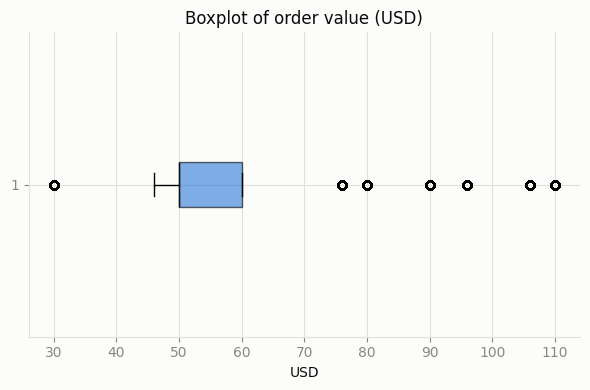

items_purchased  price_usd
1                29.99         534
2                75.98         662
                 79.98        3142
                 89.98         680
                 95.98        2036
                 105.98        248
                 109.98        944
dtype: int64

In [9]:
order_val = orders['price_usd']
q1, q3 = order_val.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = order_val[(order_val < low) | (order_val > high)]
print(f'IQR bounds: [{low:.2f}, {high:.2f}] USD | Outliers: {len(outliers)} ({len(outliers)/len(order_val)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(order_val, orientation='horizontal', patch_artist=True,
           boxprops=dict(facecolor=PALETTE[0], alpha=0.6), medianprops=dict(color=INK))
ax.set_title('Boxplot of order value (USD)')
ax.set_xlabel('USD')
plt.tight_layout()
plt.show()

display(orders.loc[outliers.index].groupby(['items_purchased', 'price_usd']).size())

**Observation:** by IQR, **25.5% of orders are outliers**, but the table above shows:
- **7,712 orders** contain **2 products**, priced 75.98–109.98 USD, above the upper bound.
- **534 orders** contain 1 product, all priced **29.99 USD** (the lowest price), below the lower bound.

Order value only takes a few fixed levels, so IQR is not a good fit. These are **real values**, not errors → **not removed**.

→ After cleaning, **no rows were removed** (no missing data, no duplicates, outliers are real values).

## 5. Feature Engineering

### 5.1. Item-level table `item_df`
The `orders` table only records the total of the whole order, so when an order contains 2 products we cannot tell which product the money belongs to. To compute revenue per product, the notebook therefore uses the `order_items` table (1 row = 1 product in an order), adds the product names and computes gross profit.

In [10]:
item_df = items.merge(products[['product_id', 'product_name']], on='product_id', how='left')
item_df['gross_profit'] = item_df['price_usd'] - item_df['cogs_usd']

print('Rows in order_items:', len(items), '| Rows after merge:', len(item_df))
item_df.head()

Rows in order_items: 40025 | Rows after merge: 40025


,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,product_name,gross_profit
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50


### 5.2. Extract year / month from created_at

In [11]:
for t in (orders, item_df):
    t['year'] = t['created_at'].dt.year
    t['month'] = t['created_at'].dt.month
    t['year_month'] = t['created_at'].dt.to_period('M')

orders[['created_at', 'year', 'month', 'year_month']].head()

,created_at,year,month,year_month
0,2012-03-19 10:42:46,2012,3,2012-03
1,2012-03-19 19:27:37,2012,3,2012-03
2,2012-03-20 06:44:45,2012,3,2012-03
3,2012-03-20 09:41:45,2012,3,2012-03
4,2012-03-20 11:28:15,2012,3,2012-03


## 6. Exploratory Data Analysis (EDA) & Pareto

### 6.1. Key metrics (KPIs)

In [12]:
kpi = pd.Series({
    'Orders': orders['order_id'].nunique(),
    'Customers': orders['user_id'].nunique(),
    'Items sold': len(item_df),
    'Revenue (USD)': item_df['price_usd'].sum(),
    'Gross profit (USD)': item_df['gross_profit'].sum(),
    'Gross margin (%)': item_df['gross_profit'].sum() / item_df['price_usd'].sum() * 100,
    'AOV - average order value (USD)': orders['price_usd'].mean(),
    'Orders with a second product (%)': (orders['items_purchased'] > 1).mean() * 100,
})
kpi.to_frame('value')

,value
Orders,32313.00
Customers,31696.00
Items sold,40025.00
Revenue (USD),1938509.75
Gross profit (USD),1216139.50
Gross margin (%),62.74
AOV - average order value (USD),59.99
Orders with a second product (%),23.87


**Observation:** over 3 years the store had **32,313 orders** from **31,696 customers**, revenue of **1.94 million USD** and gross profit of **1.22 million USD** (62.7% margin).
- AOV is **59.99 USD**. About **23.9%** of orders include a second product.

#### KPIs by year

In [13]:
kpi_year = (orders.groupby('year')
                  .agg(orders=('order_id', 'nunique'),
                       customers=('user_id', 'nunique'),
                       aov_usd=('price_usd', 'mean'),
                       cross_sell_pct=('items_purchased', lambda s: (s > 1).mean() * 100),
                       months=('year_month', 'nunique'))
                  .join(item_df.groupby('year').agg(revenue=('price_usd', 'sum'),
                                                    gross_profit=('gross_profit', 'sum'))))
kpi_year['gross_margin_pct'] = kpi_year['gross_profit'] / kpi_year['revenue'] * 100
kpi_year['revenue_per_month'] = kpi_year['revenue'] / kpi_year['months']
kpi_year

,orders,customers,aov_usd,cross_sell_pct,months,revenue,gross_profit,gross_margin_pct,revenue_per_month
year,,,,,,,,,
2012,2586,2569,49.99,0.00,10,129274.14,78873.00,61.01,12927.41
2013,7447,7343,52.81,2.23,12,393247.87,241596.50,61.44,32770.66
2014,16860,16547,63.80,33.93,12,1075612.19,679722.50,63.19,89634.35
2015,5420,5327,62.80,33.67,3,340375.55,215947.50,63.44,113458.52


**Observation – KPIs by year:**
- **AOV rose from 49.99 USD (2012) to ~63 USD (2014–2015)**, as the share of orders with a second product rose from 0% to ~34%.
- **Gross margin rose steadily** from 61.0% to 63.4%, as the newer, higher-margin products sold more.
- **Average monthly revenue** grew from ~12.9 thousand USD (2012) to ~113.5 thousand USD (2015).
- The `months` column shows that 2012 has only 10 months and 2015 only 3 months of data, so years are compared using average monthly revenue (`revenue_per_month`), not totals.

### 6.2. Revenue by month

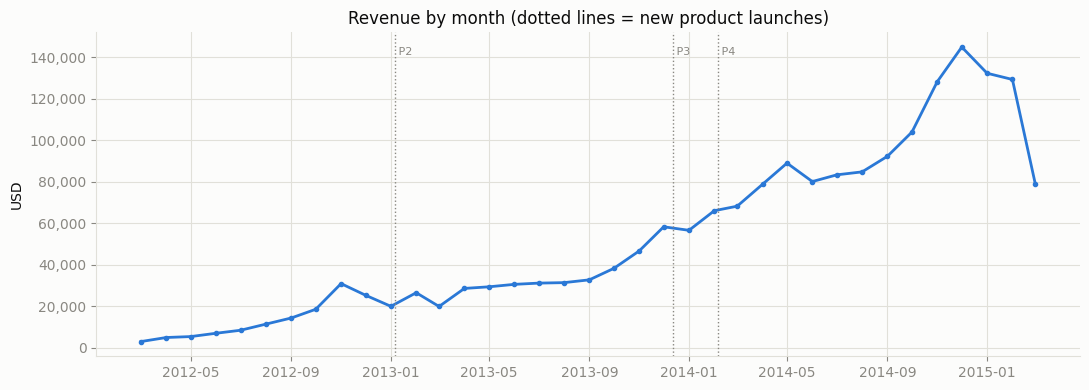

Revenue by year:
year
2012      129,274
2013      393,248
2014    1,075,612
2015      340,376


In [14]:
monthly = item_df.groupby('year_month')['price_usd'].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.values, color=PALETTE[0], marker='o', markersize=3, linewidth=2)
for _, row in products.iloc[1:].iterrows():  # mark the launch dates of products 2, 3, 4
    ax.axvline(row['created_at'], color=MUTED, linestyle=':', linewidth=1)
    ax.text(row['created_at'], monthly.max(), f" P{row['product_id']}", color=MUTED, fontsize=8, va='top')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_title('Revenue by month (dotted lines = new product launches)')
ax.set_ylabel('USD')
plt.tight_layout()
plt.show()

print('Revenue by year:'); print(item_df.groupby('year')['price_usd'].sum().map('{:,.0f}'.format).to_string())

**Observation:** revenue grew steadily, from ~3 thousand USD (03/2012) to a peak of **144,823 USD in 12/2014**. Revenue in 2014 (1.08 million USD) was **2.7 times** that of 2013 (both full 12-month years).
- Revenue started growing quickly around 09/2013, before products 3 and 4 were launched, and kept growing once all 4 products were on sale. The chart only shows that these events happened at the same time; it is not enough evidence that new products caused the growth.
- Revenue is highest at the end of the year (11–12/2012, 11–12/2014), in line with the holiday shopping season.
- The sharp drop in 03/2015 is **only because the data stops on 19/03**, not a real trend.

### 6.3. Pareto: which products generate 80% of revenue and gross profit?

In [15]:
def pareto_table(data, dim, value, agg='sum'):       # reusable function: Pareto table (aggregate, sort, share, cumulative share, group)
    t = (data.groupby(dim, as_index=False)
             .agg(total=(value, agg))
             .sort_values('total', ascending=False)
             .reset_index(drop=True))
    t['pct'] = t['total'] * 100 / t['total'].sum()
    t['cum_pct'] = t['pct'].cumsum()
    t['group'] = np.where(t['cum_pct'] - t['pct'] < 80, 'Top group (80%)', 'Others')
    return t


def plot_pareto(t, dim, title, ylabel, ax=None):
    # bars = value, line = cumulative %, 80% threshold
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    colors = np.where(t['group'] == 'Top group (80%)', PALETTE[1], '#A9A9A9')
    bars = ax.bar(t[dim].astype(str), t['total'], color=colors, edgecolor=INK, linewidth=0.5)
    ax.bar_label(bars, labels=[f'{p:.1f}%' for p in t['pct']], fontsize=8, padding=2)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.grid(axis='x', visible=False)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right', rotation_mode='anchor')

    ax2 = ax.twinx()
    ax2.plot(t[dim].astype(str), t['cum_pct'], color=PALETTE[0], marker='o', linewidth=2, label='Cumulative (%)')
    ax2.axhline(80, color=PALETTE[7], linestyle='--', linewidth=1.5, label='80% threshold')
    ax2.set_ylim(0, 105)
    ax2.set_ylabel('Cumulative share (%)', color=PALETTE[0], fontweight='bold')
    ax2.grid(False)
    ax2.spines['right'].set_visible(True)

    handles = [Patch(facecolor=PALETTE[1], label='Top group (80%)'),
               Patch(facecolor='#A9A9A9', label='Others')] + ax2.get_legend_handles_labels()[0]
    ax2.legend(handles=handles, loc='center right', fontsize=8)
    ax.set_title(title, fontweight='bold')
    return ax

Table 1: Revenue Pareto by product


,product_name,total,pct,cum_pct,group
0,The Original Mr. Fuzzy,1211057.74,62.47,62.47,Top group (80%)
1,The Forever Love Bear,347702.04,17.94,80.41,Top group (80%)
2,The Birthday Sugar Panda,229260.15,11.83,92.24,Others
3,The Hudson River Mini bear,150489.82,7.76,100.00,Others


Table 2: Gross-profit Pareto by product (with gross margin)


,product_name,total,pct,cum_pct,group,gross_margin_pct
0,The Original Mr. Fuzzy,738893.00,60.76,60.76,Top group (80%),61.01
1,The Forever Love Bear,217350.00,17.87,78.63,Top group (80%),62.51
2,The Birthday Sugar Panda,157027.50,12.91,91.54,Top group (80%),68.49
3,The Hudson River Mini bear,102869.00,8.46,100.00,Others,68.36


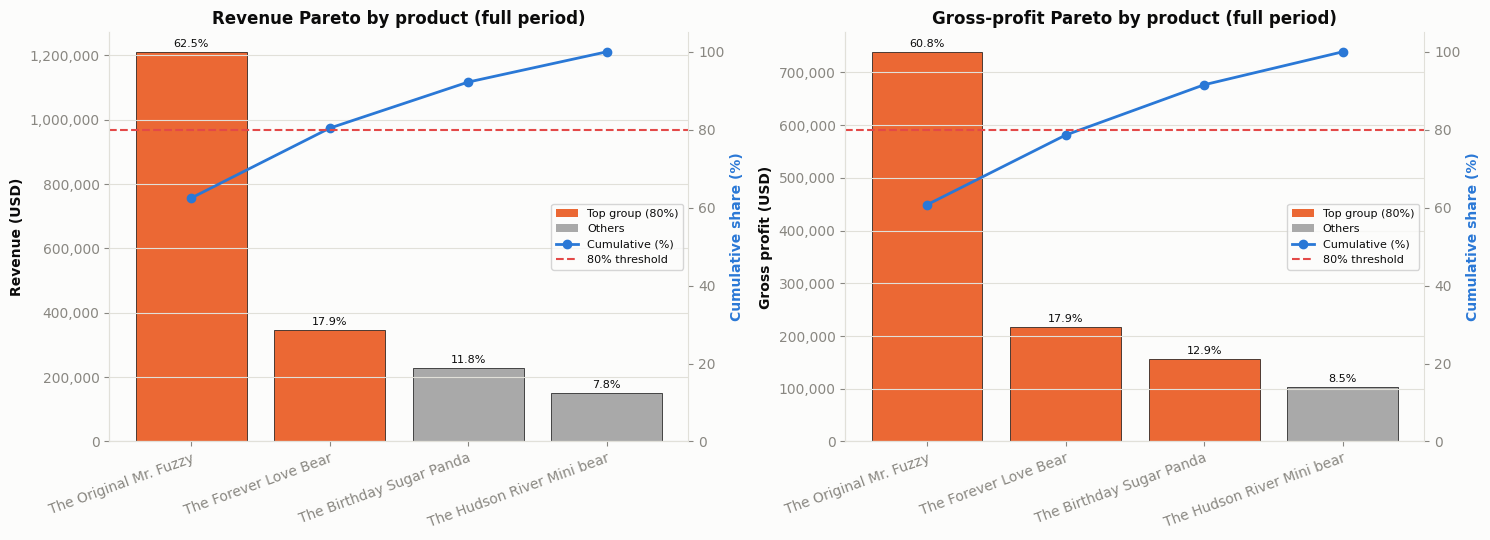

In [16]:
pareto_rev = pareto_table(item_df, 'product_name', 'price_usd') # pareto_table(data, dim, value)
pareto_gp = pareto_table(item_df, 'product_name', 'gross_profit')

# Gross margin of each product, shown with the gross-profit Pareto table
margin = (pareto_gp.set_index('product_name')['total'] / pareto_rev.set_index('product_name')['total'] * 100).rename('gross_margin_pct') # = gross profit / revenue * 100, column named gross_margin_pct
print('Table 1: Revenue Pareto by product'); display(pareto_rev)
print('Table 2: Gross-profit Pareto by product (with gross margin)'); display(pareto_gp.merge(margin, left_on='product_name', right_index=True))
# show pareto_gp, merged with margin on product_name to add the gross margin column

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_pareto(pareto_rev, 'product_name', 'Revenue Pareto by product (full period)', 'Revenue (USD)', axes[0])
plot_pareto(pareto_gp, 'product_name', 'Gross-profit Pareto by product (full period)', 'Gross profit (USD)', axes[1])
plt.tight_layout()
plt.show()

**Observation:**
- **Revenue:** **The Original Mr. Fuzzy alone accounts for 62.5%**. Adding The Forever Love Bear crosses the 80% threshold (80.4%) → **2 of 4 products (50%) generate 80% of revenue**. This is not the classic 20/80 split (the catalog has only 4 products), but revenue is still heavily concentrated in one product.
- **Gross profit:** Mr. Fuzzy accounts for 60.8%, less than its revenue share, because it has the lowest gross margin (61.0%, vs ~68% for Sugar Panda and Mini bear). The first 2 products reach only 78.6% → **3 products are needed** to exceed 80% of gross profit.

However, Mr. Fuzzy has been sold since 2012, while the other products were launched 10–23 months later, so this result is biased by **different selling periods**.

#### Fair comparison: only the period when all 4 products were on sale

The 4 products were launched at 4 different dates, so product 1 has an advantage in **time on sale**. For a fair comparison, the Pareto analysis is repeated only for the period from the last product launch to the end of the data.

Comparison period: 2014-02-05 -> 2015-03-19 (406 days, 28,561 items)
Table 3: Revenue Pareto – period with all 4 products


,product_name,total,pct,cum_pct,group
0,The Original Mr. Fuzzy,733503.27,54.27,54.27,Top group (80%)
1,The Forever Love Bear,255377.43,18.90,73.17,Top group (80%)
2,The Birthday Sugar Panda,212151.87,15.70,88.87,Top group (80%)
3,The Hudson River Mini bear,150489.82,11.13,100.00,Others


Table 4: Gross-profit Pareto – period with all 4 products (with gross margin)


,product_name,total,pct,cum_pct,group,gross_margin_pct
0,The Original Mr. Fuzzy,447526.50,52.32,52.32,Top group (80%),61.01
1,The Forever Love Bear,159637.50,18.66,70.98,Top group (80%),62.51
2,The Birthday Sugar Panda,145309.50,16.99,87.97,Top group (80%),68.49
3,The Hudson River Mini bear,102869.00,12.03,100.00,Others,68.36


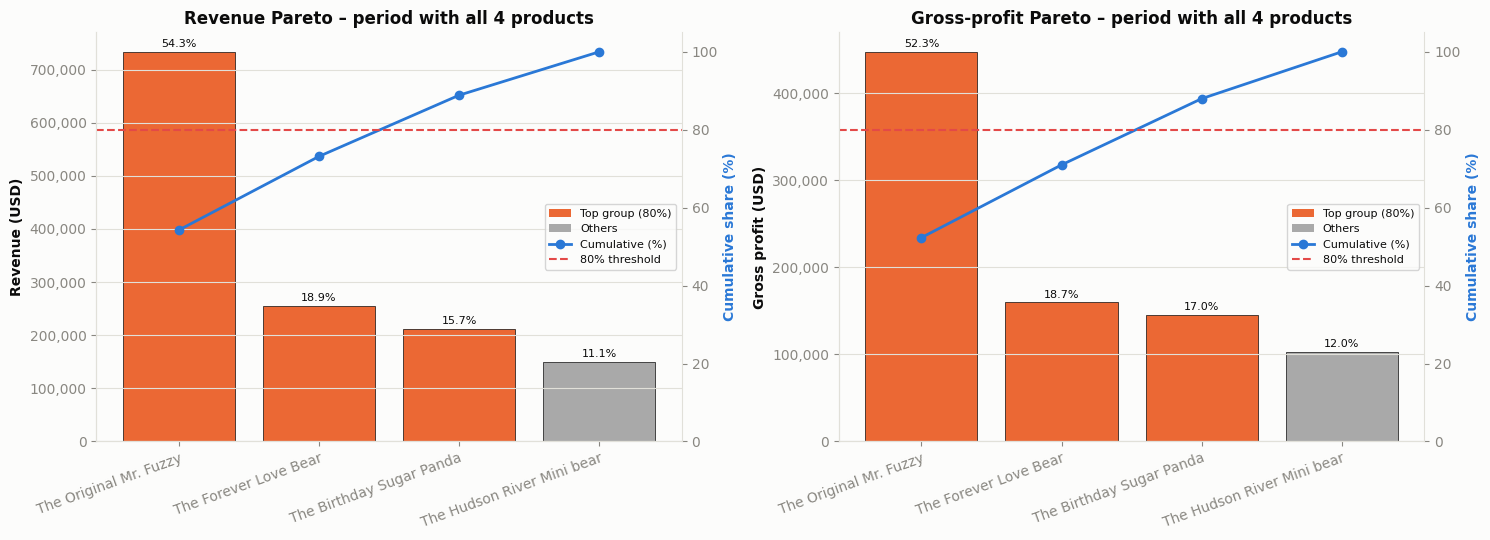

In [17]:
start_all = products['created_at'].max()
item_recent = item_df[item_df['created_at'] >= start_all]
print(f'Comparison period: {start_all.date()} -> {item_df["created_at"].max().date()} '
      f'({(item_df["created_at"].max() - start_all).days} days, {len(item_recent):,} items)')

pareto_rev_recent = pareto_table(item_recent, 'product_name', 'price_usd')
pareto_gp_recent = pareto_table(item_recent, 'product_name', 'gross_profit')

print('Table 3: Revenue Pareto – period with all 4 products'); display(pareto_rev_recent)
print('Table 4: Gross-profit Pareto – period with all 4 products (with gross margin)'); display(pareto_gp_recent.merge(margin, left_on='product_name', right_index=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_pareto(pareto_rev_recent, 'product_name', 'Revenue Pareto – period with all 4 products', 'Revenue (USD)', axes[0])
plot_pareto(pareto_gp_recent, 'product_name', 'Gross-profit Pareto – period with all 4 products', 'Gross profit (USD)', axes[1])
plt.tight_layout()
plt.show()

**Observation:** in the period when all 4 products were on sale (05/02/2014 – 19/03/2015):
- Mr. Fuzzy's share of revenue drops from 62.5% to **54.3%**. Now **3 products are needed** to reach 80% of revenue (88.9%), and also 3 products for gross profit.
- → The concentration seen above is partly because Mr. Fuzzy was on sale longer. In a fair comparison the catalog is becoming more diversified: the newer products already bring in almost half of revenue.
- Sugar Panda and Mini bear have the highest gross margins (~68.5%), so their share of gross profit is higher than their share of revenue. Conversely, Mr. Fuzzy accounts for 54.3% of revenue but only 52.3% of gross profit.

Mr. Fuzzy is still the most important product (> 50% of revenue and gross profit), but its share is not as dominant as the full-period figures suggest.

## 7. Conclusions & Recommendations

### 7.1. Key findings
- **Revenue is concentrated in one product, but becoming more diversified.** Over the full period, The Original Mr. Fuzzy accounts for 62.5% of revenue and 2 of 4 products generate 80% of revenue. Over the period when all 4 products were on sale, Mr. Fuzzy's share falls to 54.3% and 3 products are needed to reach 80%.
- **Gross profit is more spread out than revenue.** Mr. Fuzzy has the lowest gross margin (61.0%), while Sugar Panda and Mini bear earn ~68.5% → the newer products contribute more gross profit than their share of revenue.
- **Strong revenue growth:** 2014 revenue was 2.7 times that of 2013.

### 7.2. Recommendations
- **Protect the flagship product Mr. Fuzzy:** it still accounts for > 50% of revenue and gross profit, so any supply or quality problem with it has the biggest impact on the store.
- **Keep developing higher-margin products:** Sugar Panda and Mini bear earn ~68.5% gross margin. Expanding the catalog reduces dependence on Mr. Fuzzy and lifts the overall gross margin.
- **Review Mr. Fuzzy's cost or price:** the best-selling product has the lowest margin, so even a small improvement has a large effect on total gross profit.